![Banner](../images/03_07_banner_spatial_causal.png)

# Panel Designs: DiD with Spillovers, Staggered Adoption, Synthetic Control



This notebook estimates direct and spillover effects from semi-synthetic annual
county panels, 2014 to 2025, built on the 2024 adult diabetes baseline. The
three designs are simultaneous adoption, staggered adoption, and a single
treated county.

The estimators are difference-in-differences with spillover rings, staggered
difference-in-differences, and spatial synthetic control. The classes are
`SpatialDiD` and `StaggeredSpatialDiD` in `geolattice.spatial_analysis.spatialcausal`.



## Table of Contents

- [Overview](#overview)
- [Difference-in-differences and contaminated controls](#difference-in-differences-and-contaminated-controls)
- [Staggered adoption: group-time effects with clean controls](#staggered-adoption-group-time-effects-with-clean-controls)
- [Spatial synthetic control](#spatial-synthetic-control)
- [Summary and Conclusions](#summary-and-conclusions)
- [Resources](#resources)


## Overview

With repeated observations over time, each county serves as its own control: fixed differences
between counties cancel, and only *changes* are compared. Space complicates this in two ways:
untreated neighbours may be affected (contaminated controls), and adoption often spreads
across states over time.

Three semi-synthetic annual panels, 2014-2025, built on real county baselines (2024 diabetes
prevalence) with simulated common trends, factor structure and noise:

| Panel | Design | True effects |
|---|---|---|
| C1 | 10 random states adopt in 2019 | direct −0.5; spillover −0.4 / −0.2 / −0.1 at 0-40 / 40-80 / 80-120 km |
| C2 | states adopt in 2017, 2019, 2021 (6 each) | direct $-0.4-0.1k$ after $k$ years; −0.3 for never-treated counties within 60 km of treated ones |
| C3 | one county (Hinds, MS) adopts in 2021 | −1.0; spillover $-0.8(1-d/120)$ within 120 km |


**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import geolattice.spatial_analysis.spatialcausal as sc, countycausal as cc, tutorial_style as ts
from geolattice.spatial_analysis.spatialcausal import viz
ts.use()

***
## Difference-in-differences and contaminated controls

With treated group $G_i\in\{0,1\}$ and post period $P_t$, the two-way fixed-effects (TWFE) model

$$Y_{it}=\alpha_i+\lambda_t+\tau\,D_{it}+\varepsilon_{it},\qquad D_{it}=G_iP_t,$$

identifies the ATT under **parallel trends**: $\mathbb E[Y_{it}(0)-Y_{is}(0)\mid G=1]=\mathbb E[Y_{it}(0)-Y_{is}(0)\mid G=0]$.

**Spillovers break the control group.** If some untreated counties are affected, $Y_{it}=Y_{it}(0)+S_{it}$
for them, with spillover $S$. The DiD estimand becomes

$$\tau_{\text{naive}}=\tau-\mathbb E[S\mid G=0,\text{post}],$$

biased toward zero when spillovers share the sign of the effect (Butts, 2023).

**Ring model.** Let $R_{r,i}=1$ if untreated county $i$ lies at distance $(d_{r-1},d_r]$ from the
nearest treated county. Then

$$Y_{it}=\alpha_i+\lambda_t+\tau D_{it}+\sum_{r=1}^{R}\delta_r\,R_{r,i}P_t+\varepsilon_{it}.$$

Counties beyond $d_R$ form a clean control group, $\tau$ is the direct effect, and $\delta_r$ the
spillover in ring $r$. The outer ring must extend beyond the true spillover range. Estimation uses
the two-way within transformation (alternating projections, which also handle unbalanced panels)
and standard errors clustered on spatial blocks of counties, which allows for correlation between
neighbours.

**Event study.** Replacing $P_t$ by period dummies (reference = last pre-period) gives group × period
coefficients. Pre-period coefficients test parallel trends jointly; with $G$ clusters and $q$
restrictions the Hotelling-type statistic $F=W\,(G-q)/\big((G-1)q\big)\sim F(q,G-q)$ avoids the
over-rejection of a $\chi^2$ test with few clusters.


In [2]:
p1, g1 = cc.scenario_panel_rings()
print(p1, "\nadopting states:", ", ".join(sorted(map(str, p1.truth["states"]))))
did = sc.SpatialDiD(rings=(0, 40, 80, 120, 160), cluster="spatial", event_study=True).fit(p1)
res = did.result_.to_frame()[["estimate", "se", "ci_lower", "ci_upper"]]
res["truth"] = [-0.5, -0.4, -0.2, -0.1, 0.0, np.nan]
print(did.group_counts_)
print(f"pre-trend F test: F = {did.pretrend_test_['F']:.2f}, p = {did.pretrend_test_['p_value']:.3f}")
res.round(3)

SpatialPanel(units=3109, periods=12, obs=37308, treated_units=693, balanced=True) 
adopting states: AR, CT, DE, MN, MS, NC, NE, NY, OH, TN


{'treated': 693, 'control': 1444, 'ring_1': 138, 'ring_2': 291, 'ring_3': 283, 'ring_4': 260}
pre-trend F test: F = 1.22, p = 0.237


,estimate,se,ci_lower,ci_upper,truth
effect,,,,,
att,-0.544,0.040,-0.622,-0.467,-0.5
spillover_ring_1,-0.455,0.068,-0.589,-0.320,-0.4
spillover_ring_2,-0.244,0.047,-0.335,-0.152,-0.2
spillover_ring_3,-0.113,0.048,-0.207,-0.018,-0.1
spillover_ring_4,0.061,0.055,-0.046,0.168,0.0
att_naive,-0.483,0.036,-0.554,-0.412,NaN


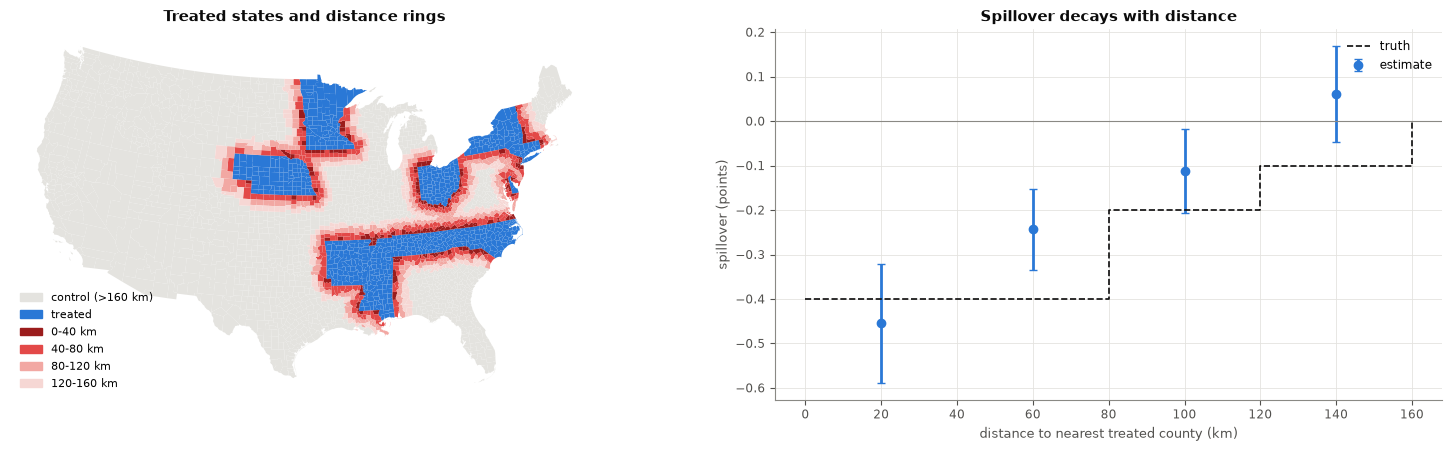

In [3]:
g1 = g1.copy()
grp = did.groups_.reindex(g1.fips).to_numpy()
labels = {0: "control (>160 km)", 1: "treated", 2: "0-40 km", 3: "40-80 km", 4: "80-120 km", 5: "120-160 km"}
g1["group"] = grp
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ts.county_map(g1, "group", ax[0], categorical=True,
              colors=["#e4e3df", ts.BLUE, "#9b1c1c", "#e34948", "#f2a8a3", "#f6d7d4"],
              legend_labels=[labels[k] for k in sorted(np.unique(grp))], title="Treated states and distance rings")
r = res.iloc[1:5]
ax[1].errorbar([20, 60, 100, 140], r.estimate, yerr=1.96 * r.se, fmt="o", capsize=3, color=ts.BLUE, label="estimate")
ax[1].step([0, 40, 80, 120, 160], [-0.4, -0.4, -0.2, -0.1, 0.0], where="post", color=ts.TRUTH, ls="--", lw=1.2, label="truth")
ax[1].axhline(0, color=ts.MUTED, lw=0.8)
ax[1].set_xlabel("distance to nearest treated county (km)"); ax[1].set_ylabel("spillover (points)")
ax[1].set_title("Spillover decays with distance"); ax[1].legend()
plt.tight_layout()

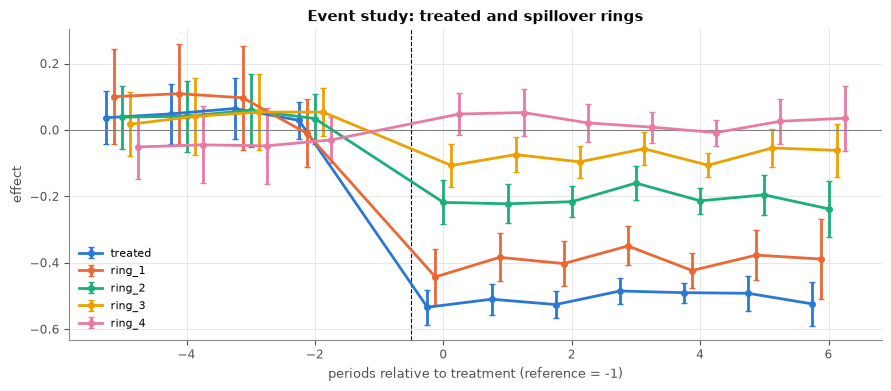

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
viz.plot_event_study(did, ax=ax)
plt.tight_layout()

The naive DiD (`att_naive`) is attenuated because about 710 contaminated counties (rings 1-3)
sit in its control group. The ring model recovers the direct effect and the decaying spillover, and the event study
shows flat pre-trends for every group.

***
## Staggered adoption: group-time effects with clean controls

When states adopt at different times, static TWFE also compares late adopters with *already-treated*
early adopters. With effects that grow over time those "forbidden comparisons" receive negative
weights, and the estimate can even change sign (Goodman-Bacon, 2021). Callaway & Sant'Anna (2021)
instead estimate each **group-time ATT** separately. For cohort $g$ (adoption year) and year $t$,

$$\text{ATT}(g,t)=\mathbb E\big[Y_t-Y_{g-1}\mid G=g\big]-\mathbb E\big[Y_t-Y_{g-1}\mid \text{clean controls at }t\big],$$

using the year before adoption as the base. `StaggeredSpatialDiD` adds space:

* every county has an **exposure time** $E_i$, the first year some county within the exposure
  distance (60 km) has adopted;
* **clean controls** at year $t$ are counties neither treated nor exposed by $\max(t,g-1)$, so
  exposed neighbours never act as controls;
* never-treated counties first exposed in year $e$ form **spillover cohorts** with their own
  $\text{ATT}_s(e,t)$.

Cells are aggregated into an overall ATT and an event study $\theta(k)=\sum_g w_g\,\text{ATT}(g,g+k)$
with cohort-size weights. Inference uses a cluster bootstrap over spatial blocks.


In [5]:
p2, g2 = cc.scenario_panel_staggered()
print(p2)
for yr, sts in p2.truth["cohorts"].items():
    print(f"  cohort {yr}: {', '.join(sorted(map(str, sts)))}")
stag = sc.StaggeredSpatialDiD(exposure_distance=60, cluster="spatial", n_boot=199).fit(p2)
cells = stag.cells_
post = cells[(cells.kind == "direct") & (cells.rel_time >= 0)]
true_att = np.average(p2.truth["event_time"](post.rel_time), weights=post["size"])
r2 = stag.result_.to_frame()[["estimate", "se", "ci_lower", "ci_upper"]]
r2["truth"] = [true_att, -0.3, true_att]
print(f"pre-trend Wald p-value: {stag.pretrend_test_['p_value']:.3f}")
r2.round(3)

SpatialPanel(units=3109, periods=12, obs=37308, treated_units=1061, balanced=True)
  cohort 2017: DC, IA, LA, NH, OK, UT
  cohort 2019: DE, IN, ME, MO, NC, ND
  cohort 2021: AL, CO, GA, MD, NJ, PA


pre-trend Wald p-value: 0.091


,estimate,se,ci_lower,ci_upper,truth
effect,,,,,
att,-0.729,0.020,-0.767,-0.691,-0.707
spillover,-0.270,0.026,-0.321,-0.219,-0.300
att_naive_twfe,-0.612,0.010,-0.632,-0.592,-0.707


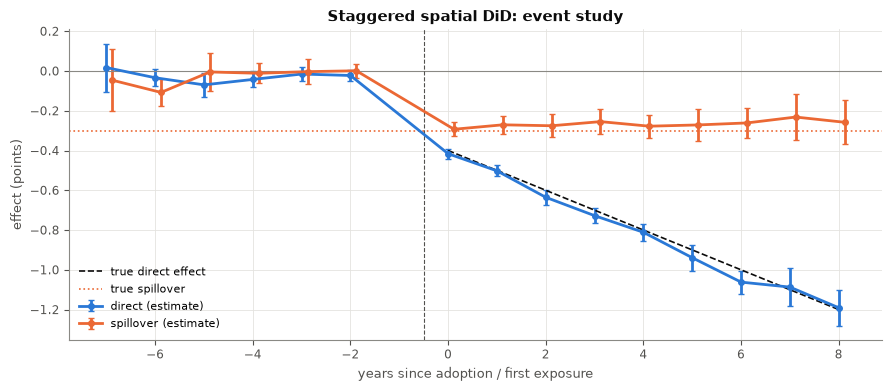

In [6]:
es = stag.event_study_
fig, ax = plt.subplots(figsize=(9, 4))
for kind, col, off in (("direct", ts.BLUE, 0.0), ("spillover", ts.ORANGE, 0.12)):
    d = es[es.kind == kind]
    ax.errorbar(d.rel_time + off, d.att, yerr=1.96 * d.se, fmt="o-", ms=4, capsize=2, color=col, label=f"{kind} (estimate)")
kk = np.arange(0, es.rel_time.max() + 1)
ax.plot(kk, p2.truth["event_time"](kk), "--", color=ts.TRUTH, lw=1.2, label="true direct effect")
ax.axhline(-0.3, color=ts.ORANGE, ls=":", lw=1.2, label="true spillover")
ax.axhline(0, color=ts.MUTED, lw=0.8); ax.axvline(-0.5, color=ts.INK2, lw=0.8, ls="--")
ax.set_xlabel("years since adoption / first exposure"); ax.set_ylabel("effect (points)")
ax.set_title("Staggered spatial DiD: event study"); ax.legend(fontsize=8)
plt.tight_layout()

The group-time estimator tracks the growing direct effect and the constant spillover; pre-period
estimates are flat. Static TWFE (`att_naive_twfe`) is biased: it mixes forbidden comparisons with
contaminated controls.

***
## Spatial synthetic control

When a single unit is treated, DiD has one treated observation per year. Synthetic control
(Abadie, Diamond & Hainmueller, 2010) builds a counterfactual as a weighted average of untreated
**donors** that tracks the treated unit before treatment:

$$\hat{\mathbf w}=\arg\min_{\mathbf w}\ \sum_{t<T_0}\Big(Y_{1t}-\sum_{j\in\mathcal D}w_jY_{jt}\Big)^2
\quad\text{s.t.}\quad w_j\ge0,\ \sum_jw_j=1,$$

$$\hat\tau_t=Y_{1t}-\sum_j\hat w_jY_{jt}\ (t\ge T_0),\qquad \widehat{\text{ATT}}=\frac{1}{T-T_0}\sum_{t\ge T_0}\hat\tau_t .$$

The weights are solved as non-negative least squares with a heavily weighted sum-to-one row,
which is exact to ~$1/M$ and fast enough for hundreds of donors and placebos.

**The spatial problem.** Neighbours share regional trends, so they are the *best-fitting* donors,
and also the ones a local policy spills onto. A contaminated donor carries part of the effect
into the counterfactual and pulls the estimate toward zero. The spatial version drops donors within a
**buffer** distance of the treated unit, estimates the spillover onto each excluded neighbour (each
gets its own synthetic control from the far donors), and reports how the estimate changes with the
buffer.

**Inference: in-space placebos.** Re-run the method pretending each donor was treated and compare
post/pre fit ratios, $\rho_j=\text{RMSPE}_{\text{post},j}/\text{RMSPE}_{\text{pre},j}$. The permutation
p-value is the rank of the treated unit's ratio among all placebos.


In [7]:
p3, g3 = cc.scenario_synthetic_control(seed=32)
near = p3.truth["spillover_by_unit"] != 0
units = list(p3.units)
print(p3, f"\n{near.sum()} counties within 120 km of the treated county receive spillover")
rows, fits = {}, {}
for b in (0, 120):
    m = sc.SpatialSyntheticControl(buffer=b).fit(p3)
    fits[b] = m
    wn = m.weights_[[u for u in m.weights_.index if near[units.index(u)]]].sum()
    rows[f"buffer {b} km"] = {"ATT": m.att_, "permutation p": m.p_value_, "pre-period RMSPE": m.pre_rmspe_,
                              "weight on contaminated donors": wn, "donors": len(m.donors_)}
print("true ATT: -1.0")
pd.DataFrame(rows).T.round(3)

SpatialPanel(units=213, periods=12, obs=2556, treated_units=1, balanced=True) 
25 counties within 120 km of the treated county receive spillover
true ATT: -1.0


,ATT,permutation p,pre-period RMSPE,weight on contaminated donors,donors
buffer 0 km,-0.659,0.068,0.000,0.521,212.0
buffer 120 km,-1.056,0.369,0.021,0.000,187.0


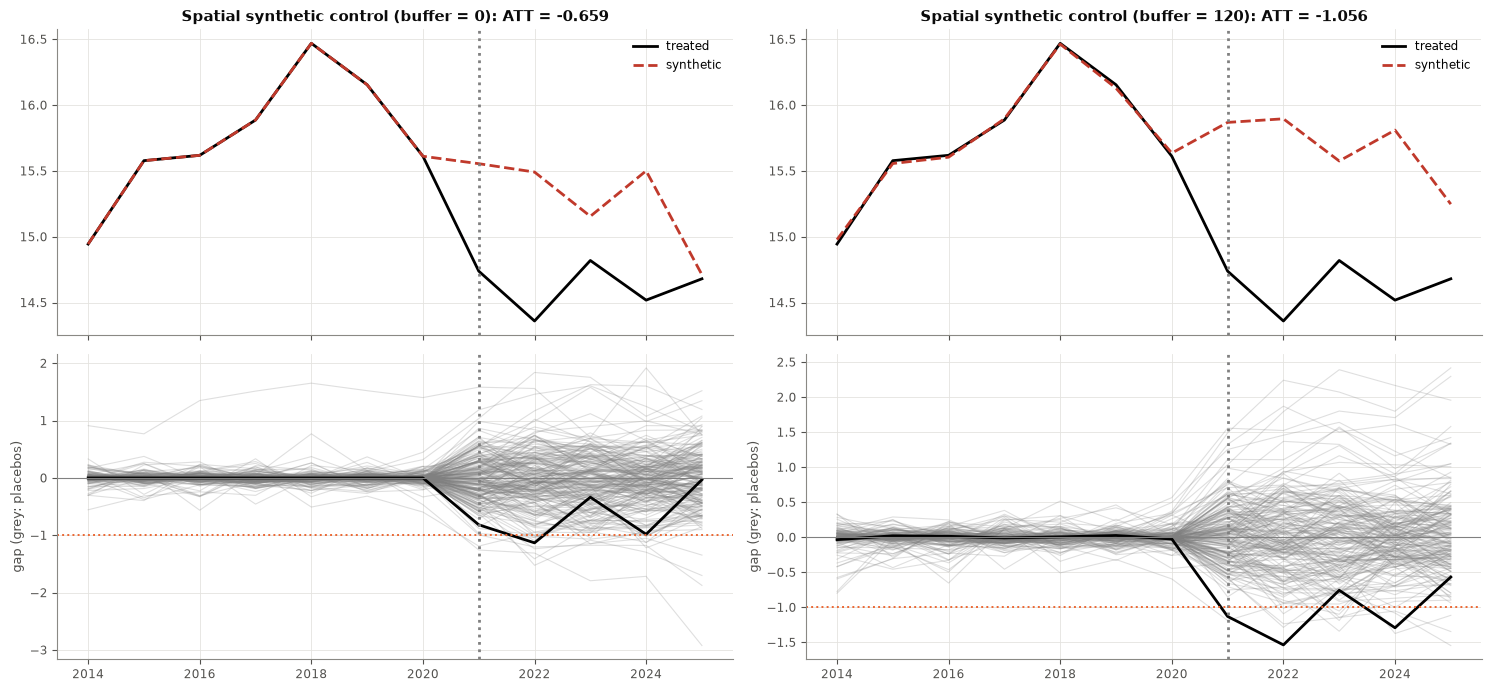

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(15, 7), sharex="col")
for col, b in enumerate((0, 120)):
    viz.plot_synthetic_control(fits[b], ax=[ax[0, col], ax[1, col]])
    ax[1, col].axhline(-1.0, color=ts.ORANGE, ls=":", lw=1.4)
plt.tight_layout()

correlation of estimated and true spillover: 0.34


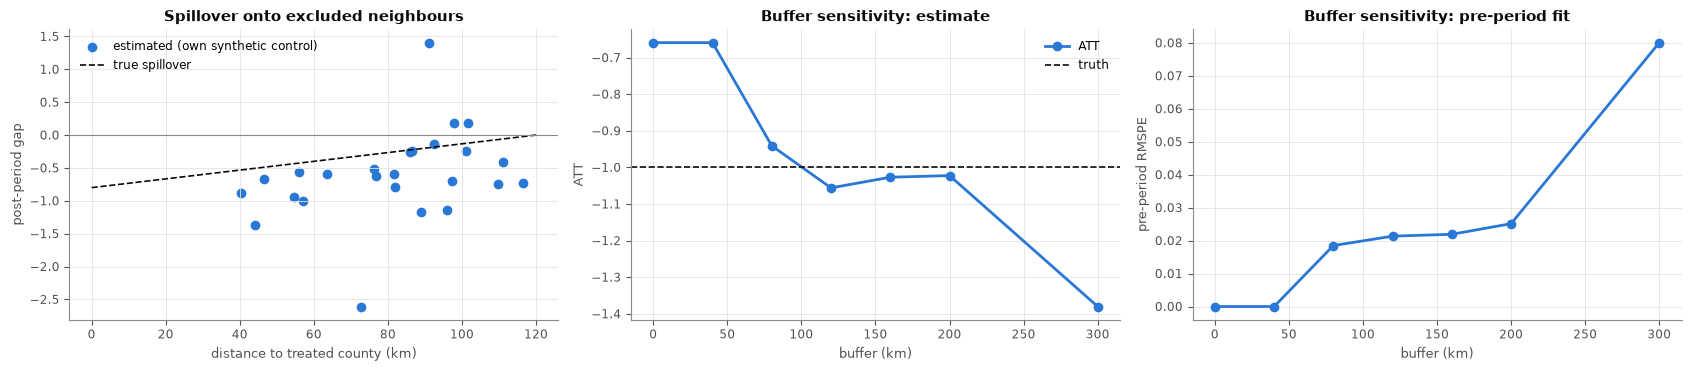

In [9]:
m = fits[120]
sp = m.spillovers()
sp["true spillover"] = p3.truth["spillover_by_unit"][[units.index(u) for u in sp.unit]]
bs = m.buffer_sensitivity([0, 40, 80, 120, 160, 200, 300])
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].scatter(sp.distance, sp.spillover, color=ts.BLUE, label="estimated (own synthetic control)")
dd = np.linspace(0, 120, 50)
ax[0].plot(dd, -0.8 * (1 - dd / 120), "--", color=ts.TRUTH, lw=1.2, label="true spillover")
ax[0].axhline(0, color=ts.MUTED, lw=0.8)
ax[0].set_xlabel("distance to treated county (km)"); ax[0].set_ylabel("post-period gap"); ax[0].legend()
ax[0].set_title("Spillover onto excluded neighbours")
ax[1].plot(bs.buffer, bs.att, "o-", color=ts.BLUE, label="ATT")
ax[1].axhline(-1.0, color=ts.TRUTH, ls="--", lw=1.2, label="truth")
ax[1].set_xlabel("buffer (km)"); ax[1].set_ylabel("ATT"); ax[1].legend()
ax[1].set_title("Buffer sensitivity: estimate")
ax[2].plot(bs.buffer, bs.pre_rmspe, "o-", color=ts.BLUE)
ax[2].set_xlabel("buffer (km)"); ax[2].set_ylabel("pre-period RMSPE")
ax[2].set_title("Buffer sensitivity: pre-period fit")
plt.tight_layout()
print(f"correlation of estimated and true spillover: {np.corrcoef(sp.spillover, sp['true spillover'])[0, 1]:.2f}")

Without a buffer the best-fitting donors are contaminated neighbours: about half the weight goes to
counties that received spillover, and the estimate is pulled toward zero. A 120 km buffer removes
them and recovers the effect. The cost shows in the buffer curve: far donors fit the pre-period
less well.

Look at the permutation p-values: the *biased* no-buffer estimate looks significant (p ≈ 0.05),
while the accurate buffered estimate does not (p ≈ 0.37). The ratio statistic divides by
pre-period fit. With only 7 pre-treatment years and ~200 donors, a near-perfect pre-fit (RMSPE ≈ 0
without a buffer) makes the treated unit's ratio enormous. So the p-value reflects fit quality as
much as effect size, and here it rewards precisely the contaminated donors that bias the estimate.
Synthetic control inference needs long pre-periods; with short ones, judge the estimate by its
robustness to the buffer rather than by the p-value.

***
## Summary and Conclusions

1. Untreated neighbours make bad controls. Ring models turn their contamination into estimated
   spillovers and leave a clean control group.
2. With staggered adoption, estimate group-time effects with clean (unexposed, not-yet-treated)
   controls; static TWFE is biased.
3. Synthetic control favours neighbours, which are exactly the donors a local policy contaminates.
   Use a buffer, estimate spillovers on the excluded units, and show buffer sensitivity.


***
## Resources

### Papers

| Reference | Notes |
|-----------|-------|
| Butts (2023) | Spillovers contaminate the DiD control group |
| Goodman-Bacon (2021) | TWFE puts negative weight on already-treated comparisons |
| Callaway & Sant'Anna (2021) | Group-time ATTs with not-yet-treated controls |
| Abadie, Diamond & Hainmueller (2010) | Synthetic control |

### In this library

| Object | Role |
|--------|------|
| `SpatialDiD` | Two-way fixed effects with distance rings and an event study |
| `StaggeredSpatialDiD` | Group-time effects that drop exposed neighbours from the controls |
| Spatial synthetic control | Donor weights with a distance buffer and in-space placebos |
| `viz.plot_event_study` | Event-study coefficients |
